In [1]:
import re
import pandas as pd
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path.cwd().parent
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)

RESULTS = PROJECT_ROOT / "results" / "lab06"
RESULTS.mkdir(parents=True, exist_ok=True)
print("course folder:", PROJECT_ROOT.name)

course folder: utp-machine-learning


## Part A — Tabular Q-learning in a 4×4 GridWorld

In [3]:
rng = np.random.default_rng(42)
ROWS, COLS = 4, 4
START, GOAL, TRAP = (0, 0), (3, 3), (1, 3)
ACTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1)]  # up, down, left, right
ACTION_NAMES = ["up", "down", "left", "right"]
ARROWS = {"up": (0, 1), "down": (0, -1), "left": (-1, 0), "right": (1, 0)}

def step(state, action):
    """Apply one action. Returns (next_state, reward, done)."""
    r, c = state
    dr, dc = ACTIONS[action]
    next_state = (min(max(r + dr, 0), ROWS - 1), min(max(c + dc, 0), COLS - 1))
    if next_state == GOAL:
        return next_state, 1.0, True
    if next_state == TRAP:
        return next_state, -1.0, True
    return next_state, -0.04, False

In [5]:
Q = np.zeros((ROWS, COLS, len(ACTIONS)))
alpha, gamma = 0.15, 0.95
epsilon, min_epsilon = 1.0, 0.05

def choose_action(state, explore=True):
    if explore and rng.random() < epsilon:
        return int(rng.integers(len(ACTIONS)))  # explore: random move
    return int(np.argmax(Q[state]))  # exploit: best known move

training_returns = []
for episode in range(5000):
    state, episode_return = START, 0.0
    for _ in range(100):
        action = choose_action(state)
        next_state, reward, done = step(state, action)
        episode_return += reward
        target = reward if done else reward + gamma * np.max(Q[next_state])
        Q[state][action] += alpha * (target - Q[state][action])
        state = next_state
        if done:
            break
    training_returns.append(episode_return)
    epsilon = max(min_epsilon, epsilon * 0.9985)

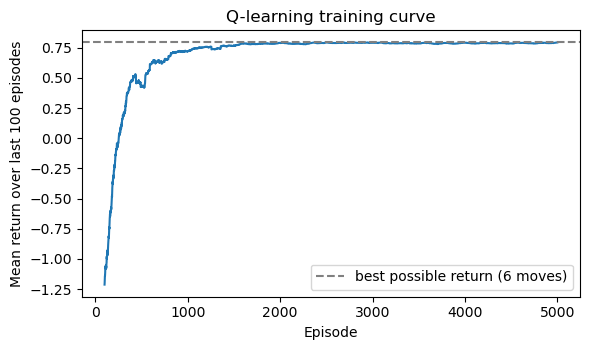

In [6]:
window = 100
moving = np.convolve(training_returns, np.ones(window) / window, mode="valid")
plt.figure(figsize=(6, 3.6))
plt.plot(np.arange(window - 1, len(training_returns)), moving)
plt.axhline(0.8, linestyle="--", color="grey", label="best possible return (6 moves)")
plt.xlabel("Episode")
plt.ylabel("Mean return over last 100 episodes")
plt.title("Q-learning training curve")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "q_learning_training_curve.png", dpi=160, bbox_inches="tight")
plt.show()

In [7]:
successes, returns = 0, []
for _ in range(200):
    state, total = START, 0.0
    for _ in range(100):
        state, reward, done = step(state, choose_action(state, explore=False))
        total += reward
        if done:
            successes += int(state == GOAL)
            break
    returns.append(total)

print("success rate:", successes / 200)
print("mean return:", round(float(np.mean(returns)), 3))
print("learned action at start:", ACTION_NAMES[choose_action(START, explore=False)])

# added: save the evaluation results to results/lab06/
summary = pd.DataFrame([{
    "success_rate": successes / 200,
    "mean_return": round(float(np.mean(returns)), 3),
    "learned_action_at_start": ACTION_NAMES[choose_action(START, explore=False)],
}])
summary.to_csv(RESULTS / "evaluation_summary.csv", index=False)

success rate: 1.0
mean return: 0.8
learned action at start: down


## Part B — The Q-table is the model: save it and read the policy

In [8]:
q_path = MODELS / "gridworld_q_table.npy"
np.save(q_path, Q)
Q_loaded = np.load(q_path)

policy = np.full((ROWS, COLS), "", dtype=object)
for r in range(ROWS):
    for c in range(COLS):
        policy[r, c] = "GOAL" if (r, c) == GOAL else "TRAP" if (r, c) == TRAP \
            else ACTION_NAMES[int(np.argmax(Q_loaded[r, c]))]
print(policy)

# added: save the printed policy grid to results/lab06/
pd.DataFrame(policy).to_csv(RESULTS / "greedy_policy.csv", index=False, header=False)

[['down' 'down' 'down' 'left']
 ['down' 'down' 'down' 'TRAP']
 ['down' 'down' 'down' 'down']
 ['right' 'right' 'right' 'GOAL']]


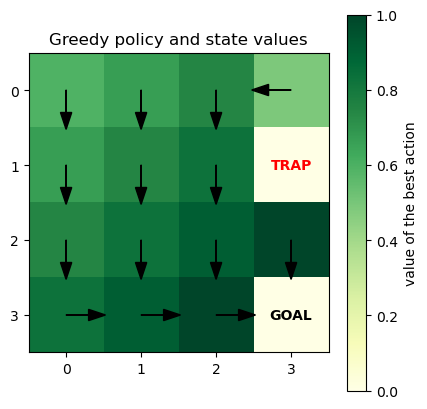

In [9]:
def plot_policy(Q_table, title, filename=None):  # added: filename
    values = Q_table.max(axis=2)
    plt.figure(figsize=(4.4, 4.2))
    plt.imshow(values, cmap="YlGn")
    plt.colorbar(label="value of the best action")
    for r in range(ROWS):
        for c in range(COLS):
            if (r, c) == GOAL:
                plt.text(c, r, "GOAL", ha="center", va="center", fontweight="bold")
            elif (r, c) == TRAP:
                plt.text(c, r, "TRAP", ha="center", va="center", color="red", fontweight="bold")
            else:
                dx, dy = ARROWS[ACTION_NAMES[int(np.argmax(Q_table[r, c]))]]
                plt.arrow(c, r, 0.3 * dx, -0.3 * dy, head_width=0.15, color="black")
    plt.xticks(range(COLS))
    plt.yticks(range(ROWS))
    plt.title(title)
    plt.tight_layout()
    if filename:  # added: save the figure to results/lab06/
        plt.savefig(RESULTS / filename, dpi=160, bbox_inches="tight")
    plt.show()

plot_policy(Q_loaded, "Greedy policy and state values", "greedy_policy_values.png")

## Try it yourself (predictions to check by retraining)

In [10]:
def run_experiment(step_cost=-0.04, trap=(1, 3), gamma=0.95, decay=0.9985,
                   episodes=5000, seed=42):
    rng_exp = np.random.default_rng(seed)
    Q_exp = np.zeros((ROWS, COLS, len(ACTIONS)))
    eps = 1.0

    def step_exp(state, action):
        r, c = state
        dr, dc = ACTIONS[action]
        nxt = (min(max(r + dr, 0), ROWS - 1), min(max(c + dc, 0), COLS - 1))
        if nxt == GOAL:
            return nxt, 1.0, True
        if nxt == trap:
            return nxt, -1.0, True
        return nxt, step_cost, False

    # training: same Q-learning update as Part A
    for _ in range(episodes):
        state = START
        for _ in range(100):
            if rng_exp.random() < eps:
                action = int(rng_exp.integers(len(ACTIONS)))
            else:
                action = int(np.argmax(Q_exp[state]))
            nxt, reward, done = step_exp(state, action)
            target = reward if done else reward + gamma * np.max(Q_exp[nxt])
            Q_exp[state][action] += alpha * (target - Q_exp[state][action])
            state = nxt
            if done:
                break
        eps = max(min_epsilon, eps * decay)

    # evaluation: greedy policy, exploration off
    state, total, steps = START, 0.0, 0
    for _ in range(100):
        state, reward, done = step_exp(state, int(np.argmax(Q_exp[state])))
        total += reward
        steps += 1
        if done:
            break
    outcome = "goal" if state == GOAL else "trap" if state == trap else "timeout"
    return Q_exp, {"outcome": outcome, "steps": steps, "return": round(total, 3)}

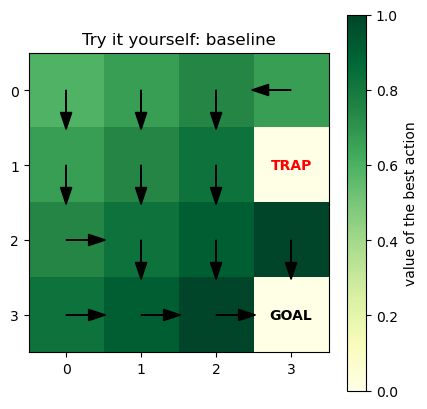

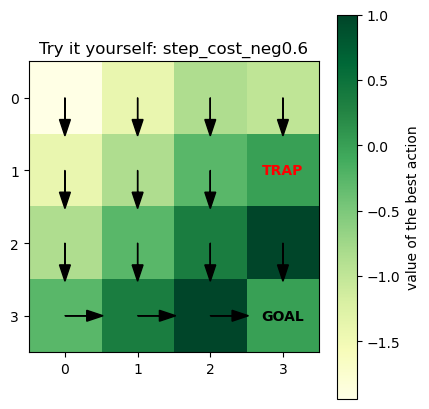

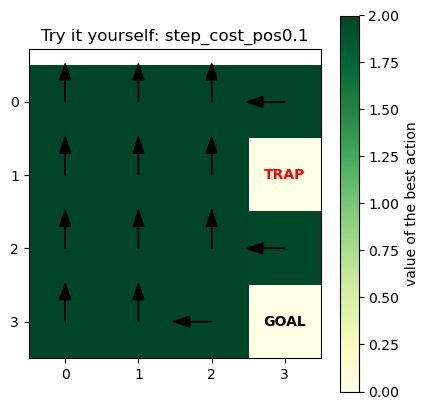

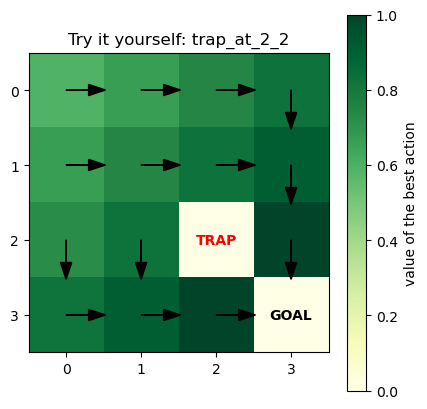

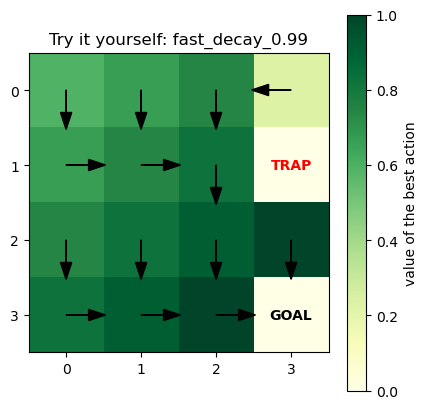

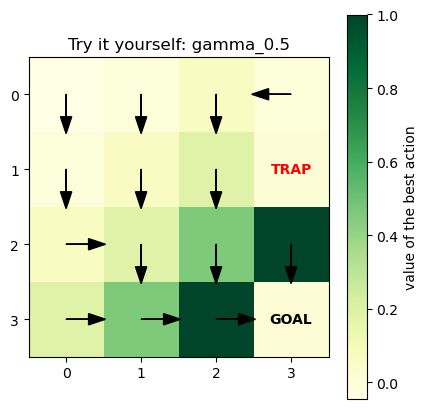

         experiment  outcome  steps  return
0          baseline     goal      6     0.8
1  step_cost_neg0.6     goal      6    -2.0
2  step_cost_pos0.1  timeout    100    10.0
3       trap_at_2_2     goal      6     0.8
4   fast_decay_0.99     goal      6     0.8
5         gamma_0.5     goal      6     0.8


In [11]:
experiments = [
    ("baseline", {}),
    ("step_cost_neg0.6", {"step_cost": -0.6}),
    ("step_cost_pos0.1", {"step_cost": 0.1}),
    ("trap_at_2_2", {"trap": (2, 2)}),
    ("fast_decay_0.99", {"decay": 0.99}),
    ("gamma_0.5", {"gamma": 0.5}),
]

rows = []
for name, settings in experiments:
    Q_exp, result = run_experiment(**settings)
    rows.append({"experiment": name, **result})
    TRAP = settings.get("trap", (1, 3))  # so plot_policy labels the right trap cell
    plot_policy(Q_exp, f"Try it yourself: {name}", f"try_{name}.png")

TRAP = (1, 3)  # put the original trap back

summary_try = pd.DataFrame(rows)
print(summary_try)
summary_try.to_csv(RESULTS / "try_it_yourself_summary.csv", index=False)